In [1]:
# Skill dictionary for NeuraNex

job_skills = {
    "AI/ML Engineer": [
        "Python", "Machine Learning", "Deep Learning",
        "TensorFlow", "PyTorch", "NLP",
        "NumPy", "Pandas", "Scikit-learn"
    ],

    "Data Analyst": [
        "SQL", "Excel", "Power BI", "Tableau",
        "Python", "Data Visualization", "Statistics", "Pandas"
    ],

    "Data Scientist": [
        "Python", "Statistics", "Machine Learning",
        "Pandas", "NumPy", "Scikit-learn",
        "SQL", "Data Visualization"
    ],

    "Software Developer": [
        "Java", "C++", "Python", "Data Structures",
        "Algorithms", "OOP", "Git", "SQL"
    ],

    "Web Developer": [
        "HTML", "CSS", "JavaScript", "React",
        "Node.js", "Git", "REST API", "Web Development"
    ],

    "Cybersecurity Analyst": [
        "Network Security", "Linux", "SIEM",
        "Ethical Hacking", "Cryptography", "Python",
        "Cybersecurity", "Vulnerability Assessment"
    ],

    "Cloud Engineer": [
        "AWS", "Azure", "Cloud Computing", "Linux",
        "Docker", "Networking", "Terraform", "Cloud Security"
    ],

    "Database Administrator": [
        "SQL", "MySQL", "PostgreSQL", "Oracle",
        "Database Management", "Linux",
        "Database Security", "Backup"
    ],

    "DevOps Engineer": [
        "Docker", "Kubernetes", "Jenkins", "Git",
        "CI/CD", "AWS", "Linux", "Terraform"
    ],

    "Mobile App Developer": [
        "Android", "Kotlin", "Java", "Flutter",
        "Dart", "Firebase", "Mobile Development", "Git"
    ],

    "QA/Test Engineer": [
        "Manual Testing", "Selenium", "Java", "Python",
        "JUnit", "Test Automation", "API Testing", "Software Testing"
    ],

    "Business Analyst": [
        "SQL", "Excel", "Power BI", "Requirements Analysis",
        "Documentation", "Agile", "Business Analysis", "Data Analysis"
    ]
}

print("Skill dictionary created successfully!")
print("Number of job categories:", len(job_skills))

Skill dictionary created successfully!
Number of job categories: 12


In [3]:
import re

def extract_skills(text, skill_dictionary):
    """
    Extract skills found in the given resume text.
    """

    text = text.lower()
    extracted_skills = []

    for category_skills in skill_dictionary.values():
        for skill in category_skills:
            # Escape special characters such as C++, CI/CD, etc.
            pattern = r"\b" + re.escape(skill.lower()) + r"\b"

            if re.search(pattern, text):
                extracted_skills.append(skill)

    # Remove duplicate skills
    extracted_skills = list(dict.fromkeys(extracted_skills))

    return extracted_skills


print("Skill extraction function created successfully!")

Skill extraction function created successfully!


In [6]:
import pandas as pd

# Load the cleaned resume dataset
cleaned_df = pd.read_csv("../data/processed/cleaned_resumes.csv")

print("Cleaned dataset loaded successfully!")
print("Shape:", cleaned_df.shape)

Cleaned dataset loaded successfully!
Shape: (1200, 4)


In [7]:
sample_resume = cleaned_df["cleaned_resume_text"].iloc[0]

extracted_skills = extract_skills(
    sample_resume,
    job_skills
)

print("Extracted Skills:")
print(extracted_skills)

Extracted Skills:
['Python', 'Machine Learning', 'PyTorch', 'NLP', 'NumPy']


In [8]:
# Extract skills from all resumes

cleaned_df["extracted_skills"] = cleaned_df["cleaned_resume_text"].apply(
    lambda text: extract_skills(text, job_skills)
)

print("Skills extracted from all resumes successfully!")
print("Number of resumes processed:", len(cleaned_df))

Skills extracted from all resumes successfully!
Number of resumes processed: 1200


In [9]:
# View extracted skills for the first 5 resumes

cleaned_df[
    ["resume_id", "job_category", "extracted_skills"]
].head()

,resume_id,job_category,extracted_skills
0,R0001,AI/ML Engineer,"[Python, Machine Learning, PyTorch, NLP, NumPy]"
1,R0002,AI/ML Engineer,"[Python, Machine Learning, NumPy, Pandas]"
2,R0003,AI/ML Engineer,"[Python, Machine Learning, Deep Learning, Tens..."
3,R0004,AI/ML Engineer,"[Python, Machine Learning, Deep Learning, Tens..."
4,R0005,AI/ML Engineer,"[Python, Machine Learning, TensorFlow, PyTorch..."


In [10]:
from collections import Counter

# Combine all extracted skills
all_extracted_skills = []

for skills in cleaned_df["extracted_skills"]:
    all_extracted_skills.extend(skills)

# Count skill occurrences
skill_counts = Counter(all_extracted_skills)

print("Top 15 Most Common Skills:")
print(skill_counts.most_common(15))

Top 15 Most Common Skills:
[('Git', 578), ('Python', 493), ('SQL', 401), ('Linux', 332), ('Java', 252), ('Pandas', 241), ('NumPy', 166), ('Data Visualization', 165), ('AWS', 165), ('Machine Learning', 162), ('Power BI', 161), ('Statistics', 157), ('Terraform', 157), ('Excel', 154), ('Docker', 154)]


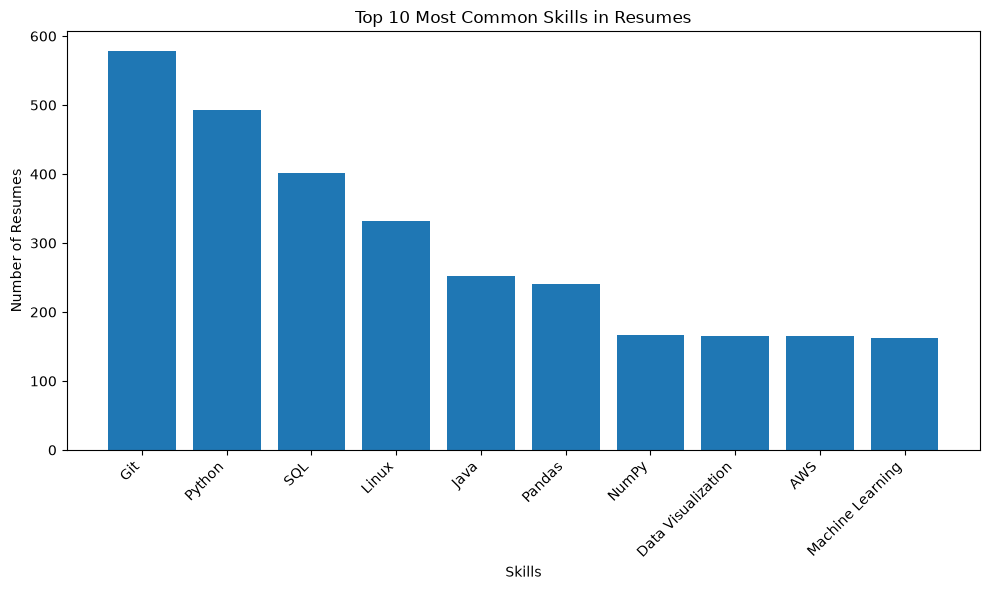

In [11]:
import matplotlib.pyplot as plt

top_10_skills = skill_counts.most_common(10)

skills = [item[0] for item in top_10_skills]
counts = [item[1] for item in top_10_skills]

plt.figure(figsize=(10, 6))

plt.bar(skills, counts)

plt.xlabel("Skills")
plt.ylabel("Number of Resumes")
plt.title("Top 10 Most Common Skills in Resumes")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
# Save the dataset with extracted skills

output_path = "../data/processed/resumes_with_skills.csv"

cleaned_df.to_csv(output_path, index=False)

print("Dataset with extracted skills saved successfully!")
print("Location:", output_path)

Dataset with extracted skills saved successfully!
Location: ../data/processed/resumes_with_skills.csv


In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

from skill_extractor import extract_skills

print("Skill extractor imported successfully!")

Skill extractor imported successfully!


In [4]:
test_resume = """
Python, Machine Learning, NLP, Pandas, NumPy,
TensorFlow, SQL and Git
"""

test_skills = extract_skills(test_resume, job_skills)

print("Extracted Skills:")
print(test_skills)

Extracted Skills:
['Python', 'Machine Learning', 'TensorFlow', 'NLP', 'NumPy', 'Pandas', 'SQL', 'Git']


In [3]:
job_skills = {
    "AI/ML Engineer": [
        "Python", "Machine Learning", "Deep Learning",
        "TensorFlow", "PyTorch", "NLP", "NumPy",
        "Pandas", "Scikit-learn"
    ],

    "Data Analyst": [
        "SQL", "Excel", "Power BI", "Tableau",
        "Python", "Data Visualization", "Statistics", "Pandas"
    ],

    "Data Scientist": [
        "Python", "Statistics", "Machine Learning",
        "Pandas", "NumPy", "Scikit-learn",
        "SQL", "Data Visualization"
    ],

    "Software Developer": [
        "Java", "C++", "Python", "Data Structures",
        "Algorithms", "OOP", "Git", "SQL"
    ],

    "Web Developer": [
        "HTML", "CSS", "JavaScript", "React",
        "Node.js", "Git", "REST API", "Web Development"
    ],

    "Cybersecurity Analyst": [
        "Network Security", "Linux", "SIEM",
        "Ethical Hacking", "Cryptography", "Python",
        "Cybersecurity", "Vulnerability Assessment"
    ],

    "Cloud Engineer": [
        "AWS", "Azure", "Cloud Computing", "Linux",
        "Docker", "Networking", "Terraform", "Cloud Security"
    ],

    "Database Administrator": [
        "SQL", "MySQL", "PostgreSQL", "Oracle",
        "Database Management", "Linux",
        "Database Security", "Backup"
    ],

    "DevOps Engineer": [
        "Docker", "Kubernetes", "Jenkins", "Git",
        "CI/CD", "AWS", "Linux", "Terraform"
    ],

    "Mobile App Developer": [
        "Android", "Kotlin", "Java", "Flutter",
        "Dart", "Firebase", "Mobile Development", "Git"
    ],

    "QA/Test Engineer": [
        "Manual Testing", "Selenium", "Java", "Python",
        "JUnit", "Test Automation", "API Testing", "Software Testing"
    ],

    "Business Analyst": [
        "SQL", "Excel", "Power BI", "Requirements Analysis",
        "Documentation", "Agile", "Business Analysis", "Data Analysis"
    ]
}

print("Skill dictionary loaded successfully!")

Skill dictionary loaded successfully!
